<a href="https://colab.research.google.com/github/donaheye/beginning--bioinformatics/blob/main/PollinatorPredictionsProject/PredictingPollinatorsByFloralMicrobes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, scipy
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram
from IPython.display import display
from pathlib import Path
import json

print("NumPy", np.__version__, "scikit-learn", sklearn.__version__, "SciPy", scipy.__version__)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})
COLORS = ['#0072B2', '#D55E00', '#009E73', '#CC79A7', '#E69F00', '#56B4E9']
OUT = Path('unsupervised_outputs'); OUT.mkdir(exist_ok=True)

def finish(name):
    plt.tight_layout()
    plt.savefig(OUT / (name + '.png'), dpi=160, bbox_inches='tight')
    plt.show()

def scatter_groups(ax, points, labels=None, title='', axis_labels=('PC1', 'PC2')):
    if labels is None:
        ax.scatter(points[:, 0], points[:, 1], color=COLORS[0], s=30, alpha=.8)
    else:
        for i, label in enumerate(np.unique(labels)):
            take = np.asarray(labels) == label
            ax.scatter(points[take, 0], points[take, 1], color=COLORS[i % len(COLORS)], s=30, alpha=.8, label=str(label))
        ax.legend(fontsize=9)
    ax.set(xlabel=axis_labels[0], ylabel=axis_labels[1], title=title)

try:
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass
try:
    import ipywidgets as widgets
    HAVE_WIDGETS = True
except ImportError:
    HAVE_WIDGETS = False
    print('Sliders unavailable: use the function calls provided below.')

NumPy 2.4.6 scikit-learn 1.6.1 SciPy 1.16.3


In [4]:
import pandas as pd

df = pd.read_csv("Dryad datset_clean.csv")
df

,Sample,Plant species,Family,Floral visitor,Isolate1,Isolate2,Isolate3,Isolate4,Isolate5
0,SA24,Kniphofia sp,Xanthorreaceae,Birds,Pantoea,0,0,0,0
1,SA23,Kniphofia sp,Xanthorreaceae,Birds,Pantoea,0,0,0,0
2,SA56,Eriosema distinctum,Fabaceae,Long-tongued insects,Pseudomonas_1,0,0,0,0
3,CdVSA17,Protea roupelliae,Proteaceae,Beetle,Acinetobacter,0,0,0,0
4,CdVSA13,Protea dracomontana,Proteaceae,Beetle,Asaia,0,0,0,0
...,...,...,...,...,...,...,...,...,...
177,CdVSA64,Protea subvestita,Proteaceae,Beetle,Wickerhamiella nectarea,0,0,0,0
178,SAF5,Protea welwitschii,Proteaceae,Beetle,Wickerhamiella nectarea,Hanseniaspora uvarum,Candida corydalis,0,0
179,SAF6,Protea welwitschii,Proteaceae,Beetle,Wickerhamiella nectarea,Metschnikowia koreensis,Hanseniaspora uvarum,Mereyozyma guillermondii,Rhodotorula mucilaginosa
180,SAF7,Protea welwitschii,Proteaceae,Beetle,Wickerhamiella nectarea,0,0,0,0


In [5]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler, StandardScaler
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('Dryad datset_clean.csv')
df.head()

,Sample,Plant species,Family,Floral visitor,Isolate1,Isolate2,Isolate3,Isolate4,Isolate5
0,SA24,Kniphofia sp,Xanthorreaceae,Birds,Pantoea,0,0,0,0
1,SA23,Kniphofia sp,Xanthorreaceae,Birds,Pantoea,0,0,0,0
2,SA56,Eriosema distinctum,Fabaceae,Long-tongued insects,Pseudomonas_1,0,0,0,0
3,CdVSA17,Protea roupelliae,Proteaceae,Beetle,Acinetobacter,0,0,0,0
4,CdVSA13,Protea dracomontana,Proteaceae,Beetle,Asaia,0,0,0,0


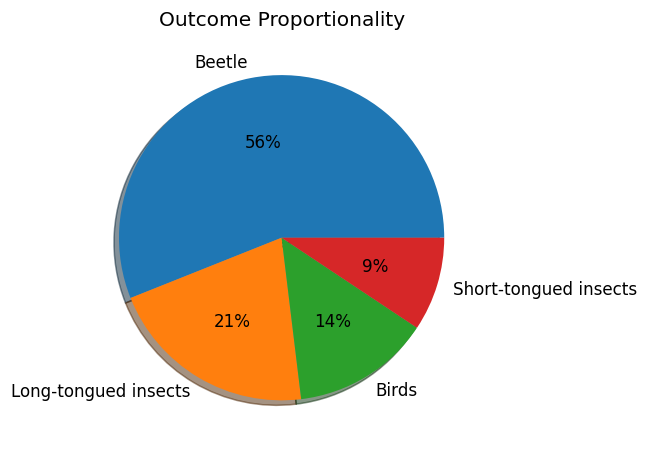

In [6]:
visitor_counts = df['Floral visitor'].value_counts()

plt.pie(visitor_counts,
        labels=visitor_counts.index,
        autopct='%.f%%', shadow=True)
plt.title('Outcome Proportionality')
plt.show()

In [7]:
import pandas as pd

from sklearn.preprocessing import MultiLabelBinarizer


df = pd.read_csv("Dryad datset_clean.csv")


df.columns = df.columns.str.strip()


isolate_columns = [
    "Isolate1",
    "Isolate2",
    "Isolate3",
    "Isolate4"
]


df["Isolates"] = df[isolate_columns].apply(
    lambda row: [
        str(isolate).strip() for isolate in row
        if pd.notna(isolate) and isolate != 0 and str(isolate).strip() != "0" and str(isolate).strip() != ""
    ],
    axis=1
)


mlb = MultiLabelBinarizer()

encoded_isolates = pd.DataFrame(
    mlb.fit_transform(df["Isolates"]),
    columns=mlb.classes_,
    index=df.index
)

mlb = MultiLabelBinarizer()

encoded_isolates = pd.DataFrame(
    mlb.fit_transform(df["Isolates"]),
    columns=mlb.classes_,
    index=df.index
)


X = encoded_isolates

y = df["Floral visitor"]

print(X)
print(y)



     Achromobacter  Acinetobacter  Arthrobacter  Asaia  Auriculibuller fuscus  \
0                0              0             0      0                      0   
1                0              0             0      0                      0   
2                0              0             0      0                      0   
3                0              1             0      0                      0   
4                0              0             0      1                      0   
..             ...            ...           ...    ...                    ...   
177              0              0             0      0                      0   
178              0              0             0      0                      0   
179              0              0             0      0                      0   
180              0              0             0      0                      0   
181              0              0             0      0                      0   

     Bacillus_1  Bacillus_2

In [9]:
dryad_cols = ['Family', 'Floral visitor', 'Plant species', 'Isolate1', 'Isolate2', 'Isolate3', 'Isolate4', 'Isolate5']

for col in dryad_cols:
    print(f"=== Class Counts for '{col}' ===")
    counts = df[col].value_counts()
    percentages = df[col].value_counts(normalize=True) * 100

    distribution = pd.DataFrame({
        'Count': counts,
        'Percentage (%)': percentages.round(2)
    })
    display(distribution.head(10))
    print("\n")

=== Class Counts for 'Family' ===


,Count,Percentage (%)
Family,,
Proteaceae,102,56.04
Iridaceae,19,10.44
Ericaceae,14,7.69
Orobanchaceae,9,4.95
Acanthaceae,7,3.85
Xanthorreaceae,6,3.30
Lamiaceae,6,3.30
Scrophulariaceae,6,3.30
Caryophyllaceae,3,1.65




=== Class Counts for 'Floral visitor' ===


,Count,Percentage (%)
Floral visitor,,
Beetle,102,56.04
Long-tongued insects,38,20.88
Birds,25,13.74
Short-tongued insects,17,9.34




=== Class Counts for 'Plant species' ===


,Count,Percentage (%)
Plant species,,
Protea welwitschii,21,11.54
Protea caffra,14,7.69
Protea roupelliae,13,7.14
Protea dracomontana,13,7.14
Protea subvestita,12,6.59
Protea repens,10,5.49
Protea laurifolia,10,5.49
Glumicalyx goseloides,6,3.30
Protea neriifolia,6,3.30


... (6 outputs left out)



=== Class Counts for 'Isolate4' ===


,Count,Percentage (%)
Isolate4,,
0,166,91.21
Klebsiella_Enterobacter,3,1.65
Hanseniaspora thailandica,2,1.10
Metschnikowia proteae,1,0.55
Rhodotorula taiwanensis,1,0.55
Rosenbergiella,1,0.55
Wickerhamomyces,1,0.55
Paraburkholderia,1,0.55
Rhodotorula mucilaginosa,1,0.55




=== Class Counts for 'Isolate5' ===


,Count,Percentage (%)
Isolate5,,
0,178,97.80
Pseudomonas_2,1,0.55
Pichia,1,0.55
Asaia,1,0.55
Rhodotorula mucilaginosa,1,0.55


In [19]:
import pandas as pd
from sklearn.preprocessing import MultiLabelBinarizer

# Load the dataset instead of referencing the undefined dryad_data variable
df = pd.read_csv('Dryad datset_clean.csv')

df.columns = df.columns.str.strip()

isolate_columns = [
    "Isolate1",
    "Isolate2",
    "Isolate3",
    "Isolate4"
]

df["Isolates"] = df[isolate_columns].apply(
    lambda row: [
        str(isolate).strip() for isolate in row
        if pd.notna(isolate) and isolate != 0 and str(isolate).strip() != "0" and str(isolate).strip() != ""
    ],
    axis=1
)

mlb = MultiLabelBinarizer()

encoded_isolates = pd.DataFrame(
    mlb.fit_transform(df["Isolates"]),
    columns=mlb.classes_,
    index=df.index
)

X = encoded_isolates
y = df["Floral visitor"]

print(X)
print(y)

     Achromobacter  Acinetobacter  Arthrobacter  Asaia  Auriculibuller fuscus  \
0                0              0             0      0                      0   
1                0              0             0      0                      0   
2                0              0             0      0                      0   
3                0              1             0      0                      0   
4                0              0             0      1                      0   
..             ...            ...           ...    ...                    ...   
177              0              0             0      0                      0   
178              0              0             0      0                      0   
179              0              0             0      0                      0   
180              0              0             0      0                      0   
181              0              0             0      0                      0   

     Bacillus_1  Bacillus_2

In [12]:
import numpy as np
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score, classification_report
from sklearn.model_selection import train_test_split, GroupKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.40, random_state=42, stratify=y
)

X_validation, X_test, y_validation, y_test = train_test_split(
    X_test, y_test, test_size=0.50, random_state=42, stratify=y_test
)

groups = df.loc[X_validation.index, "Plant species"].values
n_splits = min(len(np.unique(groups)), 5)
group_kfold = GroupKFold(n_splits=n_splits)

most_frequent_class = y_train_full.mode()[0]
simple_baseline = np.full_like(y_test, fill_value=most_frequent_class, dtype=object)

cv_scores = []
for train_idx, test_idx in group_kfold.split(X_validation, y_validation, groups=groups):
    X_tr, X_val = X_validation.iloc[train_idx], X_validation.iloc[test_idx]
    y_tr, y_val = y_validation.iloc[train_idx], y_validation.iloc[test_idx]

    rf_fold = RandomForestClassifier(
        n_estimators=100,
        random_state=36,
        max_depth=None,
        max_features='sqrt',
        max_leaf_nodes=10,
        class_weight='balanced'
    )
    rf_fold.fit(X_tr, y_tr)
    preds = rf_fold.predict(X_val)


    fold_acc = accuracy_score(y_val, preds)
    fold_f1 = f1_score(y_val, preds, average='macro')
    cv_scores.append({'fold': len(cv_scores) + 1, 'acc': fold_acc, 'f1': fold_f1})

random_forest = RandomForestClassifier(
    n_estimators=100,
    random_state=36,
    max_depth=None,
    max_features='sqrt',
    max_leaf_nodes=10,
    class_weight='balanced'
)
random_forest.fit(X_train_full, y_train_full)

proba = random_forest.predict_proba(X_test)
predictions = random_forest.predict(X_test)

accuracy = accuracy_score(y_test, predictions)
rf_macro_f1 = f1_score(y_test, predictions, average='macro')

rf_baseline_accuracy = accuracy_score(y_test, simple_baseline)
rf_baseline_f1 = f1_score(y_test, simple_baseline, average='macro')
rf_balanced_accuracy = balanced_accuracy_score(y_test, predictions)

dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train_full, y_train_full)
dummy_predictions = dummy.predict(X_test)

macro_f1_dummy = f1_score(y_test, dummy_predictions, average='macro')
balanced_accuracy_dummy = balanced_accuracy_score(y_test, dummy_predictions)

print("=== Random Forest (threshold=0.5) ===")
print(f"Balanced Accuracy: {rf_balanced_accuracy:.4f}")
print(f"Macro F1: {rf_macro_f1:.4f}")
print("\Classification Report:\n", classification_report(y_test, predictions))

print(f"Baseline Accuracy: {rf_baseline_accuracy:.4f} | Baseline F1: {rf_baseline_f1:.4f}")
for score in cv_scores:
    print(f"Fold {score['fold']}: Accuracy = {score['acc']:.4f}, F1 = {score['f1']:.4f}")
print(f"Test Set Accuracy: {accuracy:.4f} | Test Set F1: {rf_macro_f1:.4f}")

print("=== Majority class baseline ====")
print(f"Balanced Accuracy: {balanced_accuracy_dummy:.4f}")
print(f"Macro F1: {macro_f1_dummy:.4f}")
print("===Classification Report===", classification_report(y_test, dummy_predictions))

<>:73: SyntaxWarning: invalid escape sequence '\C'
<>:73: SyntaxWarning: invalid escape sequence '\C'
/tmp/ipykernel_1054/524529497.py:73: SyntaxWarning: invalid escape sequence '\C'
  print("\Classification Report:\n", classification_report(y_test, predictions))


=== Random Forest (threshold=0.5) ===
Balanced Accuracy: 0.6152
Macro F1: 0.6018
\Classification Report:
                        precision    recall  f1-score   support

               Beetle       0.91      0.95      0.93        21
                Birds       0.50      0.80      0.62         5
 Long-tongued insects       0.60      0.38      0.46         8
Short-tongued insects       0.50      0.33      0.40         3

             accuracy                           0.76        37
            macro avg       0.63      0.62      0.60        37
         weighted avg       0.75      0.76      0.74        37

Baseline Accuracy: 0.5676 | Baseline F1: 0.1810
Fold 1: Accuracy = 0.3750, F1 = 0.2815
Fold 2: Accuracy = 0.8571, F1 = 0.7000
Fold 3: Accuracy = 0.7143, F1 = 0.3889
Fold 4: Accuracy = 0.7143, F1 = 0.6250
Fold 5: Accuracy = 0.8571, F1 = 0.5556
Test Set Accuracy: 0.7568 | Test Set F1: 0.6018
=== Majority class baseline ====
Balanced Accuracy: 0.2500
Macro F1: 0.1810
===Classification Re

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [13]:
from sklearn.model_selection import GroupShuffleSplit

gss_test = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_val_idx, test_idx = next(gss_test.split(X, y, groups=df['Plant species']))

X_train_val, y_train_val = X.iloc[train_val_idx], y.iloc[train_val_idx]
groups_train_val = df['Plant species'].iloc[train_val_idx]

X_test_gp, y_test_gp = X.iloc[test_idx], y.iloc[test_idx]

gss_val = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
train_idx, val_idx = next(gss_val.split(X_train_val, y_train_val, groups=groups_train_val))

X_train_gp, y_train_gp = X_train_val.iloc[train_idx], y_train_val.iloc[train_idx]
X_val_gp, y_val_gp = X_train_val.iloc[val_idx], y_train_val.iloc[val_idx]

train_plants = set(df['Plant species'].iloc[train_val_idx].iloc[train_idx])
val_plants = set(df['Plant species'].iloc[train_val_idx].iloc[val_idx])
test_plants = set(df['Plant species'].iloc[test_idx])

print(f"Total dataset size: {len(X)} samples")
print(f"Training set:   {len(X_train_gp)} samples ({len(X_train_gp)/len(X)*100:.1f}%) | Unique Plant Species: {len(train_plants)}")
print(f"Validation set: {len(X_val_gp)} samples ({len(X_val_gp)/len(X)*100:.1f}%) | Unique Plant Species: {len(val_plants)}")
print(f"Test set:       {len(X_test_gp)} samples ({len(X_test_gp)/len(X)*100:.1f}%) | Unique Plant Species: {len(test_plants)}")

assert len(train_plants.intersection(val_plants)) == 0, "Leakage between Train & Val!"
assert len(train_plants.intersection(test_plants)) == 0, "Leakage between Train & Test!"
print("\nSuccess! No plant species overlap across splits.")

Total dataset size: 182 samples
Training set:   100 samples (54.9%) | Unique Plant Species: 25
Validation set: 44 samples (24.2%) | Unique Plant Species: 9
Test set:       38 samples (20.9%) | Unique Plant Species: 9

Success! No plant species overlap across splits.


In [14]:
rf_grouped = RandomForestClassifier(
    n_estimators=100,
    random_state=36,
    max_depth=None,
    max_features='sqrt',
    max_leaf_nodes=10,
    class_weight='balanced'
)

rf_grouped.fit(X_train_gp, y_train_gp)

val_preds = rf_grouped.predict(X_val_gp)
test_preds = rf_grouped.predict(X_test_gp)

print("=== Group Split - Validation Set Evaluation ===")
print(f"Balanced Accuracy: {balanced_accuracy_score(y_val_gp, val_preds):.4f}")
print(f"Macro F1: {f1_score(y_val_gp, val_preds, average='macro'):.4f}\n")

print("=== Group Split - Test Set Evaluation ===")
print(f"Balanced Accuracy: {balanced_accuracy_score(y_test_gp, test_preds):.4f}")
print(f"Macro F1: {f1_score(y_test_gp, test_preds, average='macro'):.4f}\n")
print(classification_report(y_test_gp, test_preds, zero_division=0))

=== Group Split - Validation Set Evaluation ===
Balanced Accuracy: 0.8333
Macro F1: 0.8413

=== Group Split - Test Set Evaluation ===
Balanced Accuracy: 0.3750
Macro F1: 0.2396

                       precision    recall  f1-score   support

               Beetle       1.00      0.33      0.50        24
                Birds       0.10      0.17      0.12         6
 Long-tongued insects       0.20      1.00      0.33         4
Short-tongued insects       0.00      0.00      0.00         4

             accuracy                           0.34        38
            macro avg       0.33      0.38      0.24        38
         weighted avg       0.67      0.34      0.37        38



In [15]:
most_frequent_gp = y_train_gp.mode()[0]
simple_baseline_val = np.full_like(y_val_gp, fill_value=most_frequent_gp, dtype=object)
simple_baseline_test = np.full_like(y_test_gp, fill_value=most_frequent_gp, dtype=object)

print(f"Most frequent class in training set: {most_frequent_gp}\n")

print("=== Group Split - Baseline Validation Evaluation ===")
print(f"Balanced Accuracy: {balanced_accuracy_score(y_val_gp, simple_baseline_val):.4f}")
print(f"Macro F1: {f1_score(y_val_gp, simple_baseline_val, average='macro', zero_division=0):.4f}\n")

print("=== Group Split - Baseline Test Evaluation ===")
print(f"Balanced Accuracy: {balanced_accuracy_score(y_test_gp, simple_baseline_test):.4f}")
print(f"Macro F1: {f1_score(y_test_gp, simple_baseline_test, average='macro', zero_division=0):.4f}")

Most frequent class in training set: Beetle

=== Group Split - Baseline Validation Evaluation ===
Balanced Accuracy: 0.3333
Macro F1: 0.2648

=== Group Split - Baseline Test Evaluation ===
Balanced Accuracy: 0.2500
Macro F1: 0.1935


[[20  0  1  0]
 [ 1  4  0  0]
 [ 1  3  3  1]
 [ 0  1  1  1]]


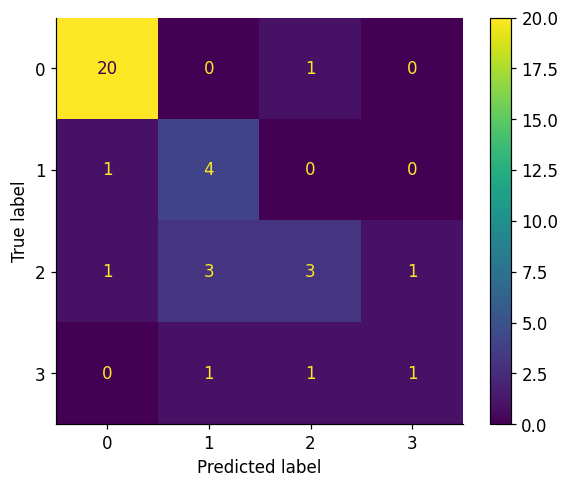

In [21]:
#making our confusion matrix :)
from sklearn import metrics

#building confusion matrix
confusion_matrix = metrics.confusion_matrix(y_test, predictions)
print(confusion_matrix)
#making display
confusion_matrix_display= metrics.ConfusionMatrixDisplay(confusion_matrix=confusion_matrix)
#plotting confusion matrix
confusion_matrix_display.plot()

In [16]:
import ipywidgets as widgets

# Fixed validation probabilities from the trained logistic regression
# p2 was calculated in the preceding cell.
jitter = np.random.default_rng(42).normal(0, 0.04, len(y_val))

@widgets.interact(
    threshold=widgets.FloatSlider(
        value=0.50, min=0.05, max=0.95, step=0.05,
        description="Threshold:",
        continuous_update=False
    )
)
def explore_threshold(threshold):

    # Change classifications WITHOUT retraining the model
    predictions = (p2 >= threshold).astype(int)
    m = metrics(y_val, predictions)

    fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))

    # LEFT: Predicted probabilities for each tumor
    for actual, label, color in [
        (0, "Actual Responder", BLUE),
        (1, "Actual Nonresponder", ORANGE)
    ]:
        mask = y_val == actual
        axs[0].scatter(
            p2[mask], y_val[mask] + jitter[mask],
            color=color, alpha=0.65, s=35, label=label
        )

    # Highlight incorrectly classified tumors
    wrong = predictions != y_val
    axs[0].scatter(
        p2[wrong], y_val[wrong] + jitter[wrong],
        marker="x", color="black", s=65,
        label="Incorrect prediction"
    )

    # Decision threshold
    axs[0].axvline(threshold, color="black", linestyle="--",
                   linewidth=2, label=f"Threshold = {threshold:.2f}")

    axs[0].set(
        xlabel="Predicted probability of Nonresponse",
        ylabel="Actual treatment response",
        yticks=[0, 1],
        yticklabels=["Responder", "Nonresponder"],
        xlim=(0, 1),
        ylim=(-0.2, 1.2),
        title="Same probabilities, different classifications"
    )
    axs[0].legend(fontsize=8, loc="upper center")

    # RIGHT: Updated confusion matrix
    show_cm(axs[1], y_val, predictions,
            f"Confusion matrix (threshold = {threshold:.2f})")

    plt.tight_layout()
    plt.show()

SyntaxError: invalid syntax (4237111221.py, line 1)